# 01 – Adat-előkészítés és baseline

Yelp Review Full minta (20 000 értékelés), tanító/validációs/teszt felbontás, TF-IDF + logisztikus regresszió baseline 5 és 3 osztályra.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

from common import (DATASET_ID, FIG_DIR, LABELS_3, LABELS_5, RESULTS_DIR, SEED, SPLIT_PATH,
                    clean_text, evaluate_and_save, results_table, save_predictions,
                    to_3class, y_for)

N_PER_CLASS = 4_000
TEST_SIZE = 0.20
VAL_SIZE = 0.10

rng = np.random.default_rng(SEED)

## 1. Adat betöltése

In [2]:
raw = load_dataset(DATASET_ID)
print(raw)

all_labels = np.asarray(raw["train"]["label"])
print("\nCsillagok eloszlása a teljes tanítóhalmazban:")
print(pd.Series(all_labels + 1).value_counts().sort_index())

README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

E:\Tanulmányok\Óbudai Egyetem\MSc - Data Science\3. szemeszter\Mesterséges intelligencia alkalmazási területei\Féléves feladat\yelp-sentiment-distilbert\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\bence\.cache\huggingface\hub\datasets--Yelp--yelp_review_full. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.

yelp_review_full/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  299MB            

yelp_review_full/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

yelp_review_full/test-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 23.5MB            

yelp_review_full/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'text'],
        num_rows: 650000
    })
    test: Dataset({
        features: ['label', 'text'],
        num_rows: 50000
    })
})

Csillagok eloszlása a teljes tanítóhalmazban:
1    130000
2    130000
3    130000
4    130000
5    130000
Name: count, dtype: int64


## 2. Mintavétel

Osztályonként 4 000 értékelés. 3 osztályos címke: 1–2★ negatív, 3★ semleges, 4–5★ pozitív.

In [3]:
idx = np.sort(np.concatenate([
    rng.choice(np.flatnonzero(all_labels == k), N_PER_CLASS, replace=False) for k in range(5)
]))

sample = raw["train"].select(idx).to_pandas().rename(columns={"label": "label5"})
sample["orig_idx"] = idx
sample["text"] = sample["text"].map(clean_text)
sample["stars"] = sample["label5"] + 1
sample["label3"] = to_3class(sample["label5"])

print(sample.shape)
sample.head()

(20000, 5)


,label5,text,orig_idx,stars,label3
0,1,"Unfortunately, the frustration of being Dr. Go...",1,2,0
1,2,Rock Bottom Brewery in Homestead is always a g...,202,3,1
2,2,"I'm HUGE SNL fan, so naturally if someone who'...",246,3,1
3,0,Other people may have had a better experience ...,314,1,0
4,1,"Meh, I've experienced better is an understatem...",317,2,0


## 3. Felbontás

Rétegzett: 72% tanító, 8% validációs, 20% teszt. A felbontás mentésre kerül, a többi notebook is ezt használja.

In [4]:
train_val, test = train_test_split(sample, test_size=TEST_SIZE, stratify=sample["label5"], random_state=SEED)
train, val = train_test_split(train_val, test_size=VAL_SIZE, stratify=train_val["label5"], random_state=SEED)

split_df = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")],
                     ignore_index=True)
split_df.to_parquet(SPLIT_PATH, index=False)
print(f"Mentve: {SPLIT_PATH}")

train, val, test = (split_df[split_df["split"] == s].reset_index(drop=True) for s in ("train", "val", "test"))
pd.crosstab(split_df["split"], split_df["stars"], margins=True)

Mentve: E:\Tanulmányok\Óbudai Egyetem\MSc - Data Science\3. szemeszter\Mesterséges intelligencia alkalmazási területei\Féléves feladat\yelp-sentiment-distilbert\data\yelp_sample_split.parquet


stars,1,2,3,4,5,All
split,,,,,,
test,800,800,800,800,800,4000
train,2880,2880,2880,2880,2880,14400
val,320,320,320,320,320,1600
All,4000,4000,4000,4000,4000,20000


## 4. Szöveghossz

,count,mean,std,min,50%,90%,max
stars,,,,,,,
1,4000.0,151.0,142.5,1.0,107.0,331.0,968.0
2,4000.0,155.4,131.9,1.0,118.0,332.0,969.0
3,4000.0,140.7,118.7,1.0,109.0,288.1,940.0
4,4000.0,124.4,110.1,1.0,94.0,260.1,923.0
5,4000.0,106.0,102.8,1.0,75.0,228.0,950.0


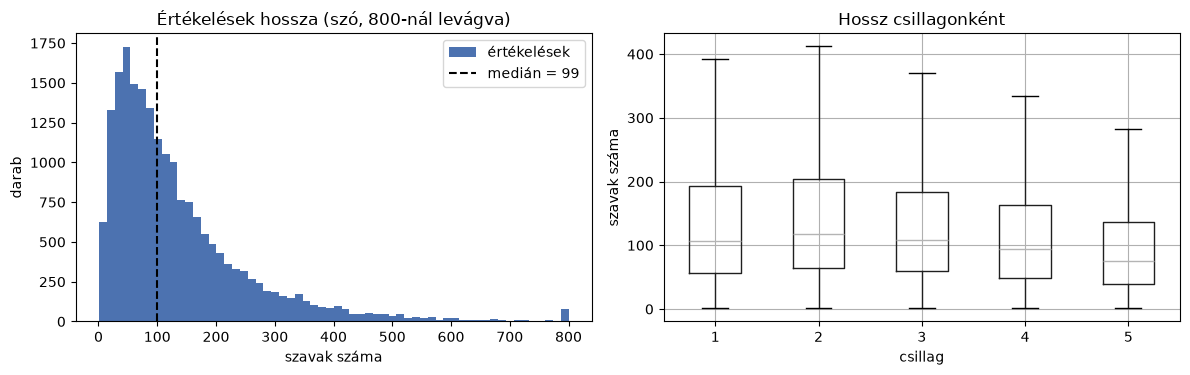

{'dataset': 'Yelp/yelp_review_full',
 'sample_size': 20000,
 'split_sizes': {'train': 14400, 'test': 4000, 'val': 1600},
 'class_counts_5': {'1★': 4000,
  '2★': 4000,
  '3★': 4000,
  '4★': 4000,
  '5★': 4000},
 'class_counts_3': {'negatív': 8000, 'semleges': 4000, 'pozitív': 8000},
 'words_median': 99.0,
 'words_mean': 135.50285,
 'words_p90': 288.0}

In [5]:
split_df["n_words"] = split_df["text"].str.split().str.len()

length_stats = split_df.groupby("stars")["n_words"].describe(percentiles=[.5, .9]).round(1)
display(length_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_df["n_words"].clip(upper=800).plot.hist(bins=60, ax=axes[0], color="#4C72B0", label="értékelések")
axes[0].axvline(split_df["n_words"].median(), color="k", ls="--", label=f"medián = {split_df['n_words'].median():.0f}")
axes[0].set(title="Értékelések hossza (szó, 800-nál levágva)", xlabel="szavak száma", ylabel="darab")
axes[0].legend()

split_df.boxplot(column="n_words", by="stars", ax=axes[1], showfliers=False)
axes[1].set(title="Hossz csillagonként", xlabel="csillag", ylabel="szavak száma")
fig.suptitle("")
fig.tight_layout()
fig.savefig(FIG_DIR / "eda_review_length.png", dpi=200, bbox_inches="tight")
plt.show()

data_stats = {
    "dataset": DATASET_ID,
    "sample_size": int(len(split_df)),
    "split_sizes": split_df["split"].value_counts().to_dict(),
    "class_counts_5": {LABELS_5[k]: int(v) for k, v in split_df["label5"].value_counts().sort_index().items()},
    "class_counts_3": {LABELS_3[k]: int(v) for k, v in split_df["label3"].value_counts().sort_index().items()},
    "words_median": float(split_df["n_words"].median()),
    "words_mean": float(split_df["n_words"].mean()),
    "words_p90": float(split_df["n_words"].quantile(.9)),
}
(RESULTS_DIR / "data_stats.json").write_text(json.dumps(data_stats, indent=2, ensure_ascii=False), encoding="utf-8")
data_stats

## 5. Többségi osztály

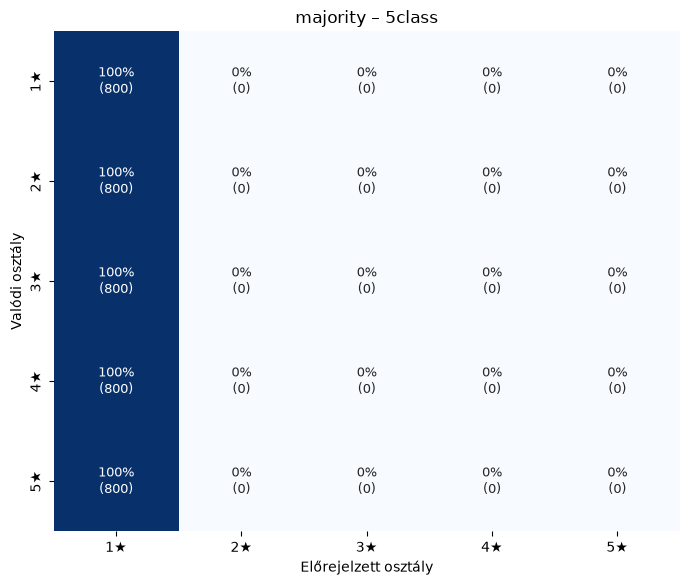

majority / 5class: accuracy=0.2000  macro-F1=0.0667


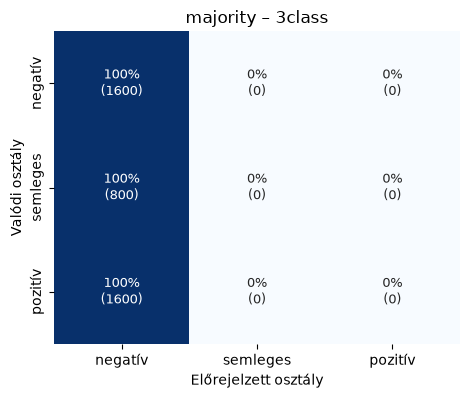

majority / 3class: accuracy=0.4000  macro-F1=0.1905


In [6]:
for task in ("5class", "3class"):
    dummy = DummyClassifier(strategy="most_frequent").fit(train["text"], y_for(train, task))
    evaluate_and_save(y_for(test, task), dummy.predict(test["text"]), "majority", task)

## 6. TF-IDF + logisztikus regresszió

Uni- és bigramok, `C` hangolása a validációs halmazon (macro-F1).

── 5class
  C=0.25  val macro-F1 = 0.5472
  C=0.5   val macro-F1 = 0.5572
  C=1     val macro-F1 = 0.5612
  C=2     val macro-F1 = 0.5621
  C=4     val macro-F1 = 0.5619
  C=8     val macro-F1 = 0.5485
  legjobb C = 2, tanítás 10.0 s


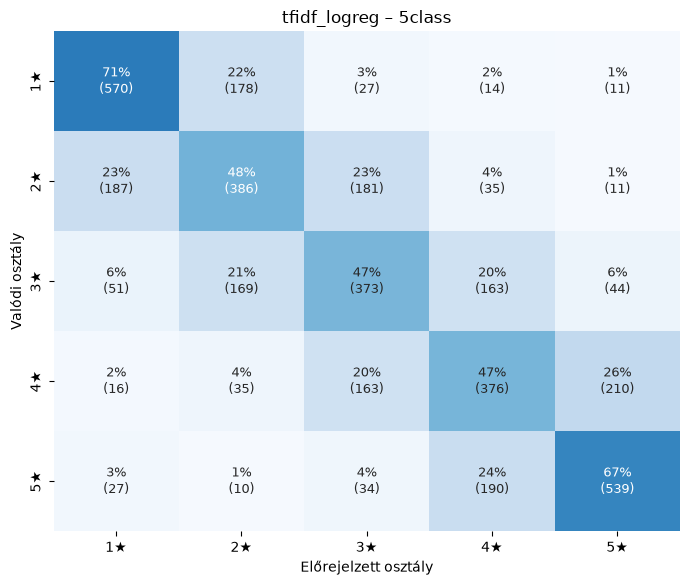

tfidf_logreg / 5class: accuracy=0.5610  macro-F1=0.5593
── 3class
  C=0.25  val macro-F1 = 0.6217
  C=0.5   val macro-F1 = 0.6765
  C=1     val macro-F1 = 0.6990
  C=2     val macro-F1 = 0.7021
  C=4     val macro-F1 = 0.7009
  C=8     val macro-F1 = 0.7025
  legjobb C = 8, tanítás 8.2 s


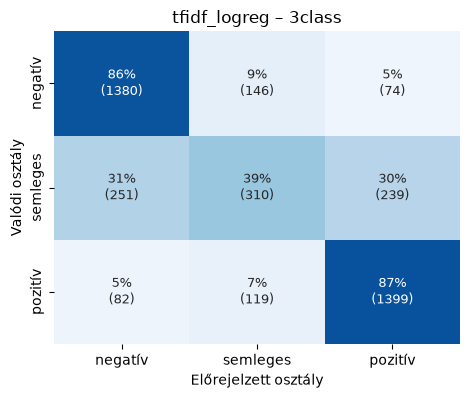

tfidf_logreg / 3class: accuracy=0.7722  macro-F1=0.7096


In [7]:
C_GRID = [0.25, 0.5, 1, 2, 4, 8]


def make_baseline(c: float):
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50_000, sublinear_tf=True),
        LogisticRegression(C=c, max_iter=2000),
    )


def tune_and_fit(task: str):
    y_tr, y_va = y_for(train, task), y_for(val, task)
    val_scores = {}
    for c in C_GRID:
        model = make_baseline(c).fit(train["text"], y_tr)
        val_scores[c] = f1_score(y_va, model.predict(val["text"]), average="macro")
        print(f"  C={c:<5} val macro-F1 = {val_scores[c]:.4f}")
    best_c = max(val_scores, key=val_scores.get)
    t0 = time.perf_counter()
    model = make_baseline(best_c).fit(train["text"], y_tr)
    return model, best_c, val_scores, time.perf_counter() - t0


baseline = {}
for task in ("5class", "3class"):
    print(f"── {task}")
    model, best_c, val_scores, secs = tune_and_fit(task)
    baseline[task] = model
    y_true, proba = y_for(test, task), model.predict_proba(test["text"])
    y_pred = proba.argmax(axis=1)
    print(f"  legjobb C = {best_c}, tanítás {secs:.1f} s")
    evaluate_and_save(y_true, y_pred, "tfidf_logreg", task,
                      extra={"best_C": best_c, "val_macro_f1_by_C": val_scores, "train_seconds": secs})
    save_predictions(test, y_true, y_pred, proba, "tfidf_logreg", task)

### 5 osztályos előrejelzés összevonása 3 osztályra

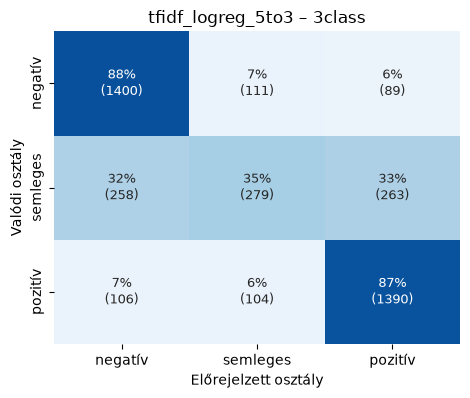

tfidf_logreg_5to3 / 3class: accuracy=0.7672  macro-F1=0.6985


,text,true,pred,correct,confidence,p_negatív,p_semleges,p_pozitív
0,"Oh, how I used to love SunUp. I was a fan when...",negatív,negatív,True,0.478857,0.478857,0.421144,0.099999
1,Dam I wish I would have known this place was h...,pozitív,pozitív,True,0.744174,0.059338,0.196488,0.744174
2,My boyfriend and I went to this place b/c he i...,semleges,negatív,False,0.581601,0.581601,0.168206,0.250193
3,Horrible experience. Rude staff. Non smoking r...,negatív,negatív,True,0.858564,0.858564,0.087724,0.053712
4,"I was incredibly nervous, given my horrible ex...",semleges,negatív,False,0.779791,0.779791,0.082785,0.137424
...,...,...,...,...,...,...,...,...
3995,"Ooh La La, Capital Grille is the most Ritzy an...",pozitív,pozitív,True,0.873896,0.069516,0.056588,0.873896
3996,Wow. Am I reading the reviews right? Are we ev...,negatív,negatív,True,0.929163,0.929163,0.050952,0.019885
3997,The best part of this place is the wait staff....,negatív,pozitív,False,0.478443,0.283116,0.238441,0.478443
3998,"Good Mexican food, but not great. We got there...",semleges,semleges,True,0.515390,0.067495,0.515390,0.417115


In [8]:
proba5 = baseline["5class"].predict_proba(test["text"])
proba3 = np.column_stack([proba5[:, 0] + proba5[:, 1], proba5[:, 2], proba5[:, 3] + proba5[:, 4]])
y_true3 = y_for(test, "3class")
evaluate_and_save(y_true3, proba3.argmax(axis=1), "tfidf_logreg_5to3", "3class")
save_predictions(test, y_true3, proba3.argmax(axis=1), proba3, "tfidf_logreg_5to3", "3class")

## 7. Legerősebb n-gramok csillagonként

In [9]:
vec, clf = baseline["5class"].named_steps.values()
vocab = np.asarray(vec.get_feature_names_out())
top_features = pd.DataFrame({LABELS_5[k]: vocab[np.argsort(clf.coef_[k])[::-1][:15]] for k in range(5)})
top_features.to_csv(RESULTS_DIR / "baseline_top_features.csv", index=False, encoding="utf-8")
top_features

,1★,2★,3★,4★,5★
0,worst,not,but,great,amazing
1,horrible,two stars,however,good,best
2,terrible,better,pretty,delicious,awesome
3,never,disappointed,average,tasty,great
4,will never,meh,decent,yum,love
5,not,bland,ok,excellent,delicious
6,rude,ok,good,definitely,perfect
7,this,mediocre,though,always,fantastic
8,no,unfortunately,not bad,bit,wonderful
9,poor,to be,bit,friendly,recommend


## 8. Összesítés

In [10]:
summary = results_table()
summary.to_csv(RESULTS_DIR / "summary.csv", index=False, encoding="utf-8")
summary.style.format({c: "{:.3f}" for c in summary.columns if c not in ("model", "task")})

,model,task,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,majority,3class,0.400,0.133,0.333,0.190,0.229
1,tfidf_logreg_5to3,3class,0.767,0.719,0.697,0.698,0.752
2,tfidf_logreg,3class,0.772,0.721,0.708,0.710,0.761
3,majority,5class,0.200,0.040,0.200,0.067,0.067
4,tfidf_logreg,5class,0.561,0.558,0.561,0.559,0.559
